In [11]:
import pandas as pd
import numpy as np
df = pd.read_csv("data - data.csv",header = None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [12]:
df.columns=[
"id", "diagnosis","radius_mean", "texture_mean", "perimeter_mean", "area_mean",
"smoothness_mean", "compactness_mean", "concavity_mean",
"concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
"radius_se", "texture_se", "perimeter_se", "area_se",
"smoothness_se", "compactness_se", "concavity_se",
"concave_points_se", "symmetry_se", "fractal_dimension_se",
"radius_worst", "texture_worst", "perimeter_worst", "area_worst",
"smoothness_worst", "compactness_worst", "concavity_worst",
"concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]

In [29]:
df.shape

(569, 32)

In [13]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [14]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['diagnosis'] = le.fit_transform(df['diagnosis'])
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
x= df.drop(['diagnosis'],axis=1)
y=df['diagnosis']
x_train,x_test,y_train,y_test= train_test_split(
    x,
    y,
    test_size=0.2,
)


In [16]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.fit_transform(x_test)

In [17]:
lr = LogisticRegression(max_iter=1000)
lr.fit(x_train_scaled,y_train)
y_pred=lr.predict(x_test_scaled)

In [18]:
print('Without PCA')
print('accuracy',accuracy_score(y_test,y_pred))
print('precision',precision_score(y_test,y_pred))
print('recall',recall_score(y_test,y_pred))
print('f1',f1_score(y_test,y_pred))

Without PCA
accuracy 0.956140350877193
precision 0.9487179487179487
recall 0.925
f1 0.9367088607594937


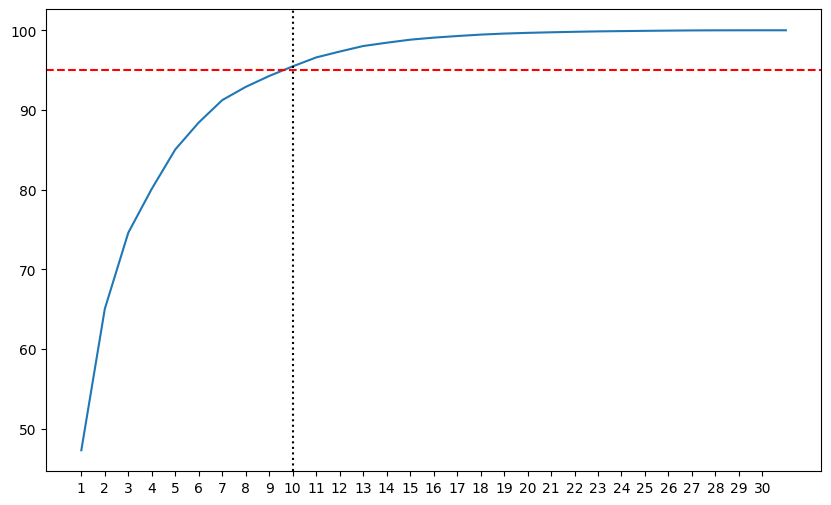

In [26]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
pca = PCA()
pca.fit(x_test_scaled)
variance=pca.explained_variance_ratio_
cumulative=np.cumsum(variance)
n = np.argmax(cumulative >= 0.95) + 1

plt.figure(figsize=(10,6))
plt.plot(range(1,32),cumulative*100)
plt.axhline(95, color="red", linestyle="--", label="95% Variance")
plt.axvline(n,color='black',linestyle=":")
plt.xticks(range(1, 31))
plt.show()


In [27]:
pca = PCA(10)
x_train_pca=pca.fit_transform(x_train_scaled)
x_test_pca=pca.transform(x_test_scaled)
model_with_pca=LogisticRegression()
model_with_pca.fit(x_train_pca,y_train)
pred_with_pca = model_with_pca.predict(x_test_pca)

In [28]:
print('With PCA')
print('accuracy',accuracy_score(y_test,pred_with_pca))
print('precision',precision_score(y_test,pred_with_pca))
print('recall',recall_score(y_test,pred_with_pca))
print('f1',f1_score(y_test,pred_with_pca))

With PCA
accuracy 0.9649122807017544
precision 0.9736842105263158
recall 0.925
f1 0.9487179487179487
